In [115]:
import hashlib
import json
import pathlib

import dotenv
import numpy as np
import pandas as pd
import tiktoken
from matplotlib import pyplot as plt
from openai import OpenAI
from tqdm.notebook import tqdm

In [116]:
assert dotenv.load_dotenv("../../env_files/secrets.env"), (
    "Failed to load environment variables from .env file"
)  # Load environment variables from .env file

In [117]:
MAX_TOKEN_LENGTH = 8191

In [ ]:
def load_chunks(corpus_path="../data/corpus_Oct2026.jsonl"):

    sha256_hash = hashlib.sha256()
    with open(corpus_path, "rb") as f:
        for byte_block in iter(lambda: f.read(4096), b""):
            sha256_hash.update(byte_block)

    file_hash = sha256_hash.hexdigest()

    with open(corpus_path, "r", encoding="utf-8") as corpus:
        for line in corpus:
            r = json.loads(line)
            if r["pmid"] == "":
                continue
            if "".join(r["abstract"]) == "":
                continue
            chunk_data = {
                "id": r["pmid"],
                "title": r["title"],
                "abstract": r["abstract"],
                "chunk_text": f"{r['title']}\n{r['abstract']}",
                "meta": {
                    k: r[k]
                    for k in (
                        "pmid",
                        "journal",
                        "pub_year",
                        "pub_types",
                        "mesh_terms",
                        "doi",
                    )
                },
            }
            chunk_data["meta"]["hash"] = file_hash
            yield chunk_data

In [119]:
def get_token_length(text, model="text-embedding-3-small"):
    """Returns the number of tokens in a text string."""
    encoding = tiktoken.encoding_for_model(model)
    return len(encoding.encode(text))

In [120]:
chunks = list(load_chunks())

In [121]:
chunk_lengths = []
for chunk in tqdm(chunks):
    chunk_lengths.append(get_token_length(chunk["chunk_text"]))

  0%|          | 0/5000 [00:00<?, ?it/s]

In [122]:
chunk_lengths_df = pd.DataFrame(chunk_lengths, columns=["token_length"])

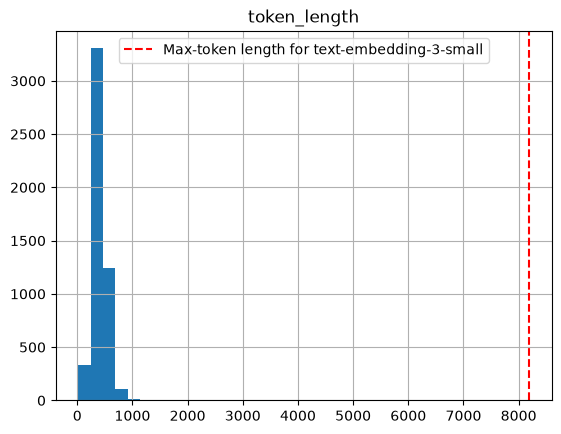

In [123]:
ax = chunk_lengths_df.hist()[0, 0]
assert max(chunk_lengths_df["token_length"]) <= MAX_TOKEN_LENGTH, (
    "Some chunks exceed the max token length for text-embedding-3-small"
)
ax.axvline(
    MAX_TOKEN_LENGTH,
    color="red",
    linestyle="--",
    label="Max-token length for text-embedding-3-small",
)
ax.legend()
plt.show()

## Note: The histogram shows that most chunks are well below the max token length for text-embedding-3-small and there are no chunks that exceed the max token length. This means that we can safely use text-embedding-3-small for embedding the chunks without worrying about truncation or loss of information.

In [124]:
MODEL, DIM = "text-embedding-3-small", 1536
client = OpenAI()

In [125]:
cache = pathlib.Path("../data/vectors/vector_embedding.npz")
cache.parent.mkdir(parents=True, exist_ok=True)

if cache.exists():
    with open(cache, "r") as fp:
        existing = np.load(str(cache), allow_pickle=True)
    done = [data["id"] for data in existing["d"]]
else:
    done = []
    existing = []
batch_size = 128
saved_pmids: list[str] = []
chunks = [c for c in chunks if c["id"] not in done]
track_saved = []
for idx in tqdm(range(0, len(chunks), batch_size)):
    batch = chunks[idx : idx + batch_size]
    texts = [c["chunk_text"] for c in batch]

    resp = client.embeddings.create(model=MODEL, input=texts)
    for chunk, emb in zip(batch, resp.data):
        v = np.array(emb.embedding, dtype=np.float32)
        chunk["embedding"] = v / np.linalg.norm(v)  # L2-normalize
        chunk["meta"]["embedding_model_id"] = f"{MODEL}_{DIM}"
        existing.append(chunk)
    ## Saving after every batch
    np.savez(cache, d=np.array(existing, dtype=object))
    saved_pmids += [c["id"] for c in batch]

  0%|          | 0/40 [00:00<?, ?it/s]

In [126]:
with open(cache, "r") as fp:
    existing = np.load(str(cache), allow_pickle=True)

In [ ]:
# def embed_all(chunks, batch_size: int = 128):
#     """
#     Embed all chunks in the given iterable of chunks using the specified model and batch size.

#     Args:
#         chunks (iterable): An iterable of chunks to be embedded.
#         batch_size (int): The number of chunks to embed in each batch. Default is 128.
#     """
#     # batch_size = 128
#     cache = pathlib.Path("../data/vectors/{MODEL}_{DIM}.jsonl")
#     ## Use existing cache if it exists, otherwise create a new one
#     # existing = (
#     #     dict(np.load(cache, allow_pickle=True)["d"].item()) if cache.exists() else {}
#     # )
#     # todo = [c for c in load_chunks() if c["id"] not in existing]
#     for i in tqdm(range(0, len(todo), batch_size)):
#         batch = todo[i : i + batch_size]
#         texts = [c["text"] for c in batch]
#         resp = client.embeddings.create(model=MODEL, input=texts)
#         for chunk, emb in zip(batch, resp.data):
#             v = np.array(emb.embedding, dtype=np.float32)
#             existing[chunk["id"]] = v / np.linalg.norm(v)  # L2-normalize

#     cache.parent.mkdir(parents=True, exist_ok=True)
#     # np.savez(cache, d=np.array(existing, dtype=object))
#     return existing